In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx


# Linear Regression 

In [1]:
import pandas as pd, numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_percentage_error

# 1. Load data (already has Close + 4 lags) and sort chronologically
df = pd.read_excel("/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx", sheet_name="Clean_Data")
df = df.sort_values("Date").reset_index(drop=True)

# 2. Target and features (all four lags are features)
features = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + features).copy()

# 3. Chronological 85/15 split (no shuffling)
split = int(len(data) * 0.85)
train, test = data.iloc[:split], data.iloc[split:]
X_train, y_train = train[features], train[target]
X_test,  y_test  = test[features],  test[target]

print("Train:", len(train), train["Date"].min().date(), "->", train["Date"].max().date())
print("Test :", len(test),  test["Date"].min().date(),  "->", test["Date"].max().date())

# 4. Fit on TRAIN only
model = LinearRegression().fit(X_train, y_train)
print("\nIntercept:", round(model.intercept_, 4))
for f, c in zip(features, model.coef_): print(f"{f}: {c:.6f}")

# 5. Predict TEST and evaluate
pred = model.predict(X_test)
mse  = mean_squared_error(y_test, pred)
print("\nTEST METRICS")
print("R-squared:", round(r2_score(y_test, pred), 6))
print("MAPE (%) :", round(mean_absolute_percentage_error(y_test, pred) * 100, 4))
print("RMSE     :", round(np.sqrt(mse), 4))
print("MSE      :", round(mse, 4))

Train: 4783 2004-01-07 -> 2023-05-04
Test : 845 2023-05-05 -> 2026-10-02

Intercept: 13.8293
y_t-1: 1.131290
y_t-2: -0.148432
y_t-3: 0.020752
y_t-4: -0.003889

TEST METRICS
R-squared: 0.99853
MAPE (%) : 0.9162
RMSE     : 1838.1191
MSE      : 3378681.9472


# Random Forest Simple with lags

In [10]:
import itertools, time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 1. Load data (raw lag values only, no window normalisation)
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

feats  = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits
#    Outer: 85% train pool / 15% test (untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

X_sub, y_sub   = sub[feats],  sub[target]
X_val, y_val   = val[feats],  val[target]
X_pool, y_pool = pool[feats], pool[target]
X_test, y_test = test[feats], test[target]

# ------------------------------------------------------------------
# 3. Metrics helper
# ------------------------------------------------------------------
def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

persist_val = metrics(y_val, val["y_t-1"])
print(f"Validation persistence baseline: RMSE={persist_val['RMSE']:.2f}, R2={persist_val['R2']:.4f}")

# ------------------------------------------------------------------
# 4. Hyperparameter grid (EVERY combination is evaluated)
#    No scaling is needed for trees.
# ------------------------------------------------------------------
grid = {
    "n_estimators":     [100, 300],
    "max_depth":        [3, 5, 10, None],
    "min_samples_leaf": [1, 5, 20, 50],
    "max_features":     [1.0, 0.5],
}
all_combos = [dict(zip(grid.keys(), v)) for v in itertools.product(*grid.values())]
print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Grid search: fit on sub-train, score on validation
# ------------------------------------------------------------------
results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    rf = RandomForestRegressor(random_state=42, n_jobs=-1, **params)
    rf.fit(X_sub, y_sub)
    m = metrics(y_val, rf.predict(X_val))
    results.append({**params, **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 6. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("rf_raw_lags_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 7. Final model: best params, refit on full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "n_estimators":     int(best["n_estimators"]),
    "max_depth":        None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
    "max_features":     float(best["max_features"]),
}
print("\nBest params:", best_params)

final_rf = RandomForestRegressor(random_state=42, n_jobs=-1, **best_params)
final_rf.fit(X_pool, y_pool)
test_pred = final_rf.predict(X_test)

tm = metrics(y_test, test_pred)
pm = metrics(y_test, test["y_t-1"])

print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")
print(f"Max prediction: {test_pred.max():.1f} | Max actual: {y_test.max():.1f}")
print("\nPersistence baseline (tomorrow = today):")
print(f"R2={pm['R2']:.6f} | MAPE={pm['MAPE']:.4f}% | RMSE={pm['RMSE']:.4f} | MSE={pm['MSE']:.4f}")

Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)
Validation persistence baseline: RMSE=409.52, R2=0.9807

Total hyperparameter combinations to test: 64
[ 1/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'max_features': 1.0} | val_RMSE=1727.51 | val_R2=0.6574
[ 2/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'max_features': 0.5} | val_RMSE=1642.96 | val_R2=0.6901
[ 3/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 1.0} | val_RMSE=1727.51 | val_R2=0.6574
[ 4/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 0.5} | val_RMSE=1642.96 | val_R2=0.6901
[ 5/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 20, 'max_features': 1.0} | val_RMSE=1727.51 | val_R2=0.6574
[ 6/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 20, 'max_features': 0.5} | val_RMSE=1642.96 | val_R2=0.6901
[ 7/64] {'n_

# Random forest with window normalization

In [11]:
import itertools, time
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

lags   = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + lags).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits (identical to the raw-lag version)
#    Outer: 85% train pool / 15% test (untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

# ------------------------------------------------------------------
# 3. WINDOW NORMALISATION (no scaler needed for trees)
#    y_t-1 / y_t-1 is always 1.0, so it is dropped as a constant feature.
# ------------------------------------------------------------------
rel_feats = ["y_t-2", "y_t-3", "y_t-4"]

def make_relative(d):
    base = d["y_t-1"].values                          # known at prediction time -> no leakage
    X_rel = d[rel_feats].values / base.reshape(-1, 1) # lags relative to yesterday's close
    y_rel = d[target].values / base                   # growth factor, around 1.0
    return X_rel, y_rel, base

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

Xsub,  ysub,  base_sub  = make_relative(sub)
Xval,  yval,  base_val  = make_relative(val)
y_val_price = val[target].values

persist_val = metrics(y_val_price, val["y_t-1"].values)
print(f"Validation persistence baseline: RMSE={persist_val['RMSE']:.2f}, R2={persist_val['R2']:.4f}")

# ------------------------------------------------------------------
# 4. Hyperparameter grid (SAME as the raw-lag version)
# ------------------------------------------------------------------
grid = {
    "n_estimators":     [100, 300],
    "max_depth":        [3, 5, 10, None],
    "min_samples_leaf": [1, 5, 20, 50],
    "max_features":     [1.0, 0.5],
}
all_combos = [dict(zip(grid.keys(), v)) for v in itertools.product(*grid.values())]
print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Grid search: fit on sub-train, score on validation IN PRICE UNITS
# ------------------------------------------------------------------
results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    rf = RandomForestRegressor(random_state=42, n_jobs=-1, **params)
    rf.fit(Xsub, ysub)
    pred_price = rf.predict(Xval) * base_val          # growth factor -> price
    m = metrics(y_val_price, pred_price)
    results.append({**params, **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 6. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("rf_window_norm_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 7. Final model: best params, refit on full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "n_estimators":     int(best["n_estimators"]),
    "max_depth":        None if pd.isna(best["max_depth"]) else int(best["max_depth"]),
    "min_samples_leaf": int(best["min_samples_leaf"]),
    "max_features":     float(best["max_features"]),
}
print("\nBest params:", best_params)

Xpool, ypool, _          = make_relative(pool)
Xtest, ytest, base_test  = make_relative(test)

final_rf = RandomForestRegressor(random_state=42, n_jobs=-1, **best_params)
final_rf.fit(Xpool, ypool)
test_pred = final_rf.predict(Xtest) * base_test       # growth factor -> price

y_test_price = test[target].values
tm = metrics(y_test_price, test_pred)
pm = metrics(y_test_price, test["y_t-1"].values)

print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")
print(f"Max prediction: {test_pred.max():.1f} | Max actual: {y_test_price.max():.1f}")
print("\nPersistence baseline (tomorrow = today):")
print(f"R2={pm['R2']:.6f} | MAPE={pm['MAPE']:.4f}% | RMSE={pm['RMSE']:.4f} | MSE={pm['MSE']:.4f}")

Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)
Validation persistence baseline: RMSE=409.52, R2=0.9807

Total hyperparameter combinations to test: 64
[ 1/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'max_features': 1.0} | val_RMSE=409.95 | val_R2=0.9807
[ 2/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 1, 'max_features': 0.5} | val_RMSE=410.22 | val_R2=0.9807
[ 3/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 1.0} | val_RMSE=409.87 | val_R2=0.9807
[ 4/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 5, 'max_features': 0.5} | val_RMSE=410.21 | val_R2=0.9807
[ 5/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 20, 'max_features': 1.0} | val_RMSE=411.14 | val_R2=0.9806
[ 6/64] {'n_estimators': 100, 'max_depth': 3, 'min_samples_leaf': 20, 'max_features': 0.5} | val_RMSE=410.60 | val_R2=0.9806
[ 7/64] {'n_estima

# Lag values used with hyperparameter tuniing LSTM

In [6]:
import itertools, random, time, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 0. Reproducibility
# ------------------------------------------------------------------
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed()

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

feats  = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits
#    Outer: 85% train pool / 15% test (test is untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

# ------------------------------------------------------------------
# 3. Helpers
# ------------------------------------------------------------------
def to_seq(X_scaled):
    """Lags are y_t-1..y_t-4; reverse so the sequence runs oldest -> newest.
    Shape: (samples, 4 time steps, 1 feature)."""
    return torch.tensor(X_scaled[:, ::-1].copy(), dtype=torch.float32).unsqueeze(-1)

def fit_scalers(train_df):
    """Scalers are fit on the training portion ONLY."""
    sx, sy = MinMaxScaler(), MinMaxScaler()
    sx.fit(train_df[feats].values)
    sy.fit(train_df[[target]].values)
    return sx, sy

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

class LSTMNet(nn.Module):
    def __init__(self, hidden_size, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1])          # last time step

def predict(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t.to(device)).cpu().numpy()

def train_model(params, Xtr, ytr, Xv=None, yv=None, max_epochs=100,
                patience=10, fixed_epochs=None):
    """
    - With validation data: trains with early stopping, returns the model
      restored to its best epoch, plus that best epoch number.
    - Without validation (final refit): trains for exactly `fixed_epochs`.
    """
    set_seed()
    model = LSTMNet(params["hidden_size"], params["num_layers"], params["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=params["batch_size"],
                    shuffle=True, generator=g)

    n_epochs = fixed_epochs if fixed_epochs is not None else max_epochs
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for ep in range(1, n_epochs + 1):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        if Xv is not None:                                   # early stopping on validation
            model.eval()
            with torch.no_grad():
                vl = loss_fn(model(Xv.to(device)), yv.to(device)).item()
            if vl < best_loss:
                best_loss, best_epoch, wait = vl, ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if Xv is not None:
        model.load_state_dict(best_state)
        return model, best_epoch
    return model, n_epochs

# ------------------------------------------------------------------
# 4. Hyperparameter grid (EVERY combination is evaluated)
# ------------------------------------------------------------------
grid = {
    "hidden_size":   [32, 64],
    "num_layers":    [1, 2],
    "dropout":       [0.0, 0.1, 0.2],
    "learning_rate": [1e-3, 1e-2],
    "batch_size":    [32, 64],
}

all_combos = []
for vals in itertools.product(*grid.values()):
    p = dict(zip(grid.keys(), vals))
    if p["num_layers"] == 1 and p["dropout"] > 0:   # dropout has no effect with 1 layer -> skip duplicates
        continue
    all_combos.append(p)

print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Grid search: fit on sub-train, score on validation
# ------------------------------------------------------------------
sx, sy = fit_scalers(sub)                         # scalers from sub-train only
Xsub_t = to_seq(sx.transform(sub[feats].values))
ysub_t = torch.tensor(sy.transform(sub[[target]].values), dtype=torch.float32)
Xval_t = to_seq(sx.transform(val[feats].values))
yval_t = torch.tensor(sy.transform(val[[target]].values), dtype=torch.float32)
y_val_true = val[target].values

results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    model, best_ep = train_model(params, Xsub_t, ysub_t, Xval_t, yval_t)
    pred = sy.inverse_transform(predict(model, Xval_t)).ravel()   # back to price units
    m = metrics(y_val_true, pred)
    results.append({**params, "best_epoch": best_ep,
                    **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | best_epoch={best_ep} "
          f"| val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 6. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("lstm_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 7. Final model: best params, refit on the full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "hidden_size":   int(best["hidden_size"]),
    "num_layers":    int(best["num_layers"]),
    "dropout":       float(best["dropout"]),
    "learning_rate": float(best["learning_rate"]),
    "batch_size":    int(best["batch_size"]),
}
best_epochs = int(best["best_epoch"])
print("\nBest params:", best_params, "| epochs:", best_epochs)

sx_f, sy_f = fit_scalers(pool)                    # scalers refit on the full 85% pool only
Xpool_t = to_seq(sx_f.transform(pool[feats].values))
ypool_t = torch.tensor(sy_f.transform(pool[[target]].values), dtype=torch.float32)
Xtest_t = to_seq(sx_f.transform(test[feats].values))

final_model, _ = train_model(best_params, Xpool_t, ypool_t, fixed_epochs=best_epochs)
test_pred = sy_f.inverse_transform(predict(final_model, Xtest_t)).ravel()

tm = metrics(test[target].values, test_pred)
print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")

Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)

Total hyperparameter combinations to test: 32
[ 1/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=49 | val_RMSE=550.51 | val_R2=0.9652
[ 2/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 64} | best_epoch=10 | val_RMSE=622.36 | val_R2=0.9555
[ 3/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 32} | best_epoch=35 | val_RMSE=413.18 | val_R2=0.9804
[ 4/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 64} | best_epoch=64 | val_RMSE=407.84 | val_R2=0.9809
[ 5/32] {'hidden_size': 32, 'num_layers': 2, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=30 | val_RMSE=608.17 | val_R2=0.9575
[ 6/32] {'hidden_size': 32, 'num_layers': 2, 'dropout': 0

# **Window Normalization** LSTM

In [7]:
import itertools, random, time, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 0. Reproducibility
# ------------------------------------------------------------------
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed()

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

feats  = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits
#    Outer: 85% train pool / 15% test (untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

# ------------------------------------------------------------------
# 3. WINDOW NORMALISATION helpers
# ------------------------------------------------------------------
def make_relative(d):
    """Divide every lag and the target by the row's own previous close (y_t-1)."""
    base = d["y_t-1"].values.reshape(-1, 1)          # known at prediction time -> no leakage
    X_rel = d[feats].values / base                   # shape (n, 4), around 1.0
    y_rel = d[[target]].values / base                # shape (n, 1), around 1.0
    return X_rel, y_rel, base.ravel()

def to_seq(X):
    """Lags are y_t-1..y_t-4; reverse to oldest -> newest.
    Shape: (samples, 4 time steps, 1 feature)."""
    return torch.tensor(X[:, ::-1].copy(), dtype=torch.float32).unsqueeze(-1)

def fit_scalers(X_rel, y_rel):
    """Scalers are fit on the training portion ONLY."""
    sx, sy = StandardScaler(), StandardScaler()
    sx.fit(X_rel); sy.fit(y_rel)
    return sx, sy

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

class LSTMNet(nn.Module):
    def __init__(self, hidden_size, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True,
                            dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)
    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1])

def predict(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t.to(device)).cpu().numpy()

def train_model(params, Xtr, ytr, Xv=None, yv=None, max_epochs=100,
                patience=10, fixed_epochs=None):
    """With validation data: early stopping, returns best-epoch model + best epoch.
       Without validation (final refit): trains exactly `fixed_epochs`."""
    set_seed()
    model = LSTMNet(params["hidden_size"], params["num_layers"], params["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=params["batch_size"],
                    shuffle=True, generator=g)

    n_epochs = fixed_epochs if fixed_epochs is not None else max_epochs
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for ep in range(1, n_epochs + 1):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        if Xv is not None:
            model.eval()
            with torch.no_grad():
                vl = loss_fn(model(Xv.to(device)), yv.to(device)).item()
            if vl < best_loss:
                best_loss, best_epoch, wait = vl, ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if Xv is not None:
        model.load_state_dict(best_state)
        return model, best_epoch
    return model, n_epochs

# ------------------------------------------------------------------
# 4. Hyperparameter grid (SAME as before: every combination is evaluated)
# ------------------------------------------------------------------
grid = {
    "hidden_size":   [32, 64],
    "num_layers":    [1, 2],
    "dropout":       [0.0, 0.1, 0.2],
    "learning_rate": [1e-3, 1e-2],
    "batch_size":    [32, 64],
}

all_combos = []
for vals in itertools.product(*grid.values()):
    p = dict(zip(grid.keys(), vals))
    if p["num_layers"] == 1 and p["dropout"] > 0:     # dropout has no effect with 1 layer
        continue
    all_combos.append(p)

print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Prepare relative data for the grid search (scalers from sub-train only)
# ------------------------------------------------------------------
Xsub_rel, ysub_rel, base_sub = make_relative(sub)
Xval_rel, yval_rel, base_val = make_relative(val)

sx, sy = fit_scalers(Xsub_rel, ysub_rel)

Xsub_t = to_seq(sx.transform(Xsub_rel))
ysub_t = torch.tensor(sy.transform(ysub_rel), dtype=torch.float32)
Xval_t = to_seq(sx.transform(Xval_rel))
yval_t = torch.tensor(sy.transform(yval_rel), dtype=torch.float32)

y_val_price = val[target].values

# Persistence baseline on validation, for reference
persist_val = metrics(y_val_price, val["y_t-1"].values)
print(f"Validation persistence baseline: RMSE={persist_val['RMSE']:.2f}, R2={persist_val['R2']:.4f}")

# ------------------------------------------------------------------
# 6. Grid search: fit on sub-train, score on validation IN PRICE UNITS
# ------------------------------------------------------------------
results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    model, best_ep = train_model(params, Xsub_t, ysub_t, Xval_t, yval_t)

    pred_rel   = sy.inverse_transform(predict(model, Xval_t)).ravel()   # growth factor
    pred_price = pred_rel * base_val                                    # back to price
    m = metrics(y_val_price, pred_price)

    results.append({**params, "best_epoch": best_ep,
                    **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | best_epoch={best_ep} "
          f"| val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 7. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("lstm_window_norm_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 8. Final model: best params, refit on full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "hidden_size":   int(best["hidden_size"]),
    "num_layers":    int(best["num_layers"]),
    "dropout":       float(best["dropout"]),
    "learning_rate": float(best["learning_rate"]),
    "batch_size":    int(best["batch_size"]),
}
best_epochs = int(best["best_epoch"])
print("\nBest params:", best_params, "| epochs:", best_epochs)

Xpool_rel, ypool_rel, _ = make_relative(pool)
Xtest_rel, ytest_rel, base_test = make_relative(test)

sx_f, sy_f = fit_scalers(Xpool_rel, ypool_rel)           # refit on full 85% pool only
Xpool_t = to_seq(sx_f.transform(Xpool_rel))
ypool_t = torch.tensor(sy_f.transform(ypool_rel), dtype=torch.float32)
Xtest_t = to_seq(sx_f.transform(Xtest_rel))

final_model, _ = train_model(best_params, Xpool_t, ypool_t, fixed_epochs=best_epochs)

pred_rel   = sy_f.inverse_transform(predict(final_model, Xtest_t)).ravel()
test_pred  = pred_rel * base_test                        # growth factor -> price

tm = metrics(test[target].values, test_pred)
pm = metrics(test[target].values, test["y_t-1"].values)  # persistence baseline

print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")
print("\nPersistence baseline (tomorrow = today):")
print(f"R2={pm['R2']:.6f} | MAPE={pm['MAPE']:.4f}% | RMSE={pm['RMSE']:.4f} | MSE={pm['MSE']:.4f}")

Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)

Total hyperparameter combinations to test: 32
Validation persistence baseline: RMSE=409.52, R2=0.9807
[ 1/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=1 | val_RMSE=410.62 | val_R2=0.9806
[ 2/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 64} | best_epoch=1 | val_RMSE=409.67 | val_R2=0.9807
[ 3/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 32} | best_epoch=2 | val_RMSE=409.24 | val_R2=0.9808
[ 4/32] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 64} | best_epoch=11 | val_RMSE=409.87 | val_R2=0.9807
[ 5/32] {'hidden_size': 32, 'num_layers': 2, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=15 | val_RMSE=409.96 | val_R2=0.9807
[ 6/

# Transformer with lag values

In [8]:
import itertools, random, time, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 0. Reproducibility
# ------------------------------------------------------------------
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed()

# ------------------------------------------------------------------
# 1. Load data (raw lag values only, no window normalisation)
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

feats  = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
SEQ_LEN = len(feats)
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits
#    Outer: 85% train pool / 15% test (untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

# ------------------------------------------------------------------
# 3. Helpers
# ------------------------------------------------------------------
def to_seq(X_scaled):
    """Lags are y_t-1..y_t-4; reverse so the sequence runs oldest -> newest.
    Shape: (samples, 4 time steps, 1 feature)."""
    return torch.tensor(X_scaled[:, ::-1].copy(), dtype=torch.float32).unsqueeze(-1)

def fit_scalers(train_df):
    """Scalers are fit on the training portion ONLY."""
    sx, sy = MinMaxScaler(), MinMaxScaler()
    sx.fit(train_df[feats].values)
    sy.fit(train_df[[target]].values)
    return sx, sy

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

class TransformerNet(nn.Module):
    def __init__(self, d_model, nhead, num_layers, dropout, seq_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(1, d_model)                                   # project 1 feature -> d_model
        self.pos = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)   # learnable positional encoding
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,
            dropout=dropout, batch_first=True
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers,
                                         enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, 1)
    def forward(self, x):
        h = self.enc(self.inp(x) + self.pos)
        return self.fc(h[:, -1])                                           # last time step

def predict(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t.to(device)).cpu().numpy()

def train_model(params, Xtr, ytr, Xv=None, yv=None, max_epochs=100,
                patience=10, fixed_epochs=None):
    """With validation data: early stopping, returns best-epoch model + best epoch.
       Without validation (final refit): trains exactly `fixed_epochs`."""
    set_seed()
    model = TransformerNet(params["d_model"], params["nhead"],
                           params["num_layers"], params["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=params["batch_size"],
                    shuffle=True, generator=g)

    n_epochs = fixed_epochs if fixed_epochs is not None else max_epochs
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for ep in range(1, n_epochs + 1):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        if Xv is not None:
            model.eval()
            with torch.no_grad():
                vl = loss_fn(model(Xv.to(device)), yv.to(device)).item()
            if vl < best_loss:
                best_loss, best_epoch, wait = vl, ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if Xv is not None:
        model.load_state_dict(best_state)
        return model, best_epoch
    return model, n_epochs

# ------------------------------------------------------------------
# 4. Hyperparameter grid (EVERY combination is evaluated)
#    nhead must divide d_model: 32/2, 32/4, 64/2, 64/4 are all valid.
#    dim_feedforward is fixed at 2 * d_model.
# ------------------------------------------------------------------
grid = {
    "d_model":       [32, 64],
    "nhead":         [2, 4],
    "num_layers":    [1, 2],
    "dropout":       [0.0, 0.1],
    "learning_rate": [1e-3, 1e-2],
    "batch_size":    [32, 64],
}

all_combos = []
for vals in itertools.product(*grid.values()):
    p = dict(zip(grid.keys(), vals))
    if p["d_model"] % p["nhead"] != 0:
        continue
    all_combos.append(p)

print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Prepare data for grid search (scalers fit on sub-train only)
# ------------------------------------------------------------------
sx, sy = fit_scalers(sub)
Xsub_t = to_seq(sx.transform(sub[feats].values))
ysub_t = torch.tensor(sy.transform(sub[[target]].values), dtype=torch.float32)
Xval_t = to_seq(sx.transform(val[feats].values))
yval_t = torch.tensor(sy.transform(val[[target]].values), dtype=torch.float32)
y_val_true = val[target].values

persist_val = metrics(y_val_true, val["y_t-1"].values)
print(f"Validation persistence baseline: RMSE={persist_val['RMSE']:.2f}, R2={persist_val['R2']:.4f}")

# ------------------------------------------------------------------
# 6. Grid search: fit on sub-train, score on validation (price units)
# ------------------------------------------------------------------
results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    model, best_ep = train_model(params, Xsub_t, ysub_t, Xval_t, yval_t)
    pred = sy.inverse_transform(predict(model, Xval_t)).ravel()
    m = metrics(y_val_true, pred)
    results.append({**params, "best_epoch": best_ep,
                    **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | best_epoch={best_ep} "
          f"| val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 7. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("transformer_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 8. Final model: best params, refit on full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "d_model":       int(best["d_model"]),
    "nhead":         int(best["nhead"]),
    "num_layers":    int(best["num_layers"]),
    "dropout":       float(best["dropout"]),
    "learning_rate": float(best["learning_rate"]),
    "batch_size":    int(best["batch_size"]),
}
best_epochs = int(best["best_epoch"])
print("\nBest params:", best_params, "| epochs:", best_epochs)

sx_f, sy_f = fit_scalers(pool)                      # refit on full 85% pool only
Xpool_t = to_seq(sx_f.transform(pool[feats].values))
ypool_t = torch.tensor(sy_f.transform(pool[[target]].values), dtype=torch.float32)
Xtest_t = to_seq(sx_f.transform(test[feats].values))

final_model, _ = train_model(best_params, Xpool_t, ypool_t, fixed_epochs=best_epochs)
test_pred = sy_f.inverse_transform(predict(final_model, Xtest_t)).ravel()

tm = metrics(test[target].values, test_pred)
pm = metrics(test[target].values, test["y_t-1"].values)

print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")
print("\nPersistence baseline (tomorrow = today):")
print(f"R2={pm['R2']:.6f} | MAPE={pm['MAPE']:.4f}% | RMSE={pm['RMSE']:.4f} | MSE={pm['MSE']:.4f}")

Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)

Total hyperparameter combinations to test: 64
Validation persistence baseline: RMSE=409.52, R2=0.9807
[ 1/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=7 | val_RMSE=410.91 | val_R2=0.9806
[ 2/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 64} | best_epoch=20 | val_RMSE=409.45 | val_R2=0.9808
[ 3/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 32} | best_epoch=7 | val_RMSE=413.51 | val_R2=0.9804
[ 4/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 64} | best_epoch=16 | val_RMSE=411.36 | val_R2=0.9806
[ 5/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.1, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=

# window normalization transformer 


In [9]:
import itertools, random, time, copy
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error,
                             r2_score, mean_absolute_percentage_error)

# ------------------------------------------------------------------
# 0. Reproducibility
# ------------------------------------------------------------------
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s)
    torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device = "cuda" if torch.cuda.is_available() else "cpu"
set_seed()

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
df = pd.read_excel(
    "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx",
    sheet_name="Clean_Data"
)
df = df.sort_values("Date").reset_index(drop=True)

feats  = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
SEQ_LEN = len(feats)
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

# ------------------------------------------------------------------
# 2. Splits
#    Outer: 85% train pool / 15% test (untouched until the end)
#    Inner: 85% sub-train / 15% validation, taken INSIDE the train pool
# ------------------------------------------------------------------
s1 = int(len(data) * 0.85)
pool, test = data.iloc[:s1], data.iloc[s1:]

s2 = int(len(pool) * 0.85)
sub, val = pool.iloc[:s2], pool.iloc[s2:]

print(f"Sub-train : {len(sub)}  ({sub.Date.min().date()} -> {sub.Date.max().date()})")
print(f"Validation: {len(val)}  ({val.Date.min().date()} -> {val.Date.max().date()})")
print(f"Test      : {len(test)}  ({test.Date.min().date()} -> {test.Date.max().date()})")

# ------------------------------------------------------------------
# 3. WINDOW NORMALISATION helpers
# ------------------------------------------------------------------
def make_relative(d):
    """Divide every lag and the target by the row's own previous close (y_t-1)."""
    base = d["y_t-1"].values.reshape(-1, 1)          # known at prediction time -> no leakage
    X_rel = d[feats].values / base                   # (n, 4), around 1.0
    y_rel = d[[target]].values / base                # (n, 1), around 1.0
    return X_rel, y_rel, base.ravel()

def to_seq(X):
    """Lags are y_t-1..y_t-4; reverse to oldest -> newest.
    Shape: (samples, 4 time steps, 1 feature)."""
    return torch.tensor(X[:, ::-1].copy(), dtype=torch.float32).unsqueeze(-1)

def fit_scalers(X_rel, y_rel):
    """Scalers are fit on the training portion ONLY."""
    sx, sy = StandardScaler(), StandardScaler()
    sx.fit(X_rel); sy.fit(y_rel)
    return sx, sy

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2":   r2_score(y_true, y_pred),
        "MAPE": mean_absolute_percentage_error(y_true, y_pred) * 100,
        "RMSE": np.sqrt(mse),
        "MSE":  mse,
        "MAE":  mean_absolute_error(y_true, y_pred),
    }

class TransformerNet(nn.Module):
    def __init__(self, d_model, nhead, num_layers, dropout, seq_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(1, d_model)                                   # 1 feature -> d_model
        self.pos = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)   # learnable positional encoding
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,
            dropout=dropout, batch_first=True
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers,
                                         enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, 1)
    def forward(self, x):
        h = self.enc(self.inp(x) + self.pos)
        return self.fc(h[:, -1])                                           # last time step

def predict(model, X_t):
    model.eval()
    with torch.no_grad():
        return model(X_t.to(device)).cpu().numpy()

def train_model(params, Xtr, ytr, Xv=None, yv=None, max_epochs=100,
                patience=10, fixed_epochs=None):
    """With validation data: early stopping, returns best-epoch model + best epoch.
       Without validation (final refit): trains exactly `fixed_epochs`."""
    set_seed()
    model = TransformerNet(params["d_model"], params["nhead"],
                           params["num_layers"], params["dropout"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=params["learning_rate"])
    loss_fn = nn.MSELoss()
    g = torch.Generator().manual_seed(SEED)
    dl = DataLoader(TensorDataset(Xtr, ytr), batch_size=params["batch_size"],
                    shuffle=True, generator=g)

    n_epochs = fixed_epochs if fixed_epochs is not None else max_epochs
    best_loss, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for ep in range(1, n_epochs + 1):
        model.train()
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss_fn(model(xb), yb).backward()
            opt.step()

        if Xv is not None:
            model.eval()
            with torch.no_grad():
                vl = loss_fn(model(Xv.to(device)), yv.to(device)).item()
            if vl < best_loss:
                best_loss, best_epoch, wait = vl, ep, 0
                best_state = copy.deepcopy(model.state_dict())
            else:
                wait += 1
                if wait >= patience:
                    break

    if Xv is not None:
        model.load_state_dict(best_state)
        return model, best_epoch
    return model, n_epochs

# ------------------------------------------------------------------
# 4. Hyperparameter grid (EVERY combination is evaluated)
#    nhead must divide d_model; dim_feedforward fixed at 2 * d_model.
# ------------------------------------------------------------------
grid = {
    "d_model":       [32, 64],
    "nhead":         [2, 4],
    "num_layers":    [1, 2],
    "dropout":       [0.0, 0.1],
    "learning_rate": [1e-3, 1e-2],
    "batch_size":    [32, 64],
}

all_combos = []
for vals in itertools.product(*grid.values()):
    p = dict(zip(grid.keys(), vals))
    if p["d_model"] % p["nhead"] != 0:
        continue
    all_combos.append(p)

print(f"\nTotal hyperparameter combinations to test: {len(all_combos)}")

# ------------------------------------------------------------------
# 5. Prepare relative data for grid search (scalers from sub-train only)
# ------------------------------------------------------------------
Xsub_rel, ysub_rel, base_sub = make_relative(sub)
Xval_rel, yval_rel, base_val = make_relative(val)

sx, sy = fit_scalers(Xsub_rel, ysub_rel)

Xsub_t = to_seq(sx.transform(Xsub_rel))
ysub_t = torch.tensor(sy.transform(ysub_rel), dtype=torch.float32)
Xval_t = to_seq(sx.transform(Xval_rel))
yval_t = torch.tensor(sy.transform(yval_rel), dtype=torch.float32)

y_val_price = val[target].values

persist_val = metrics(y_val_price, val["y_t-1"].values)
print(f"Validation persistence baseline: RMSE={persist_val['RMSE']:.2f}, R2={persist_val['R2']:.4f}")

# ------------------------------------------------------------------
# 6. Grid search: fit on sub-train, score on validation IN PRICE UNITS
# ------------------------------------------------------------------
results = []
start = time.time()
for i, params in enumerate(all_combos, 1):
    model, best_ep = train_model(params, Xsub_t, ysub_t, Xval_t, yval_t)

    pred_rel   = sy.inverse_transform(predict(model, Xval_t)).ravel()   # growth factor
    pred_price = pred_rel * base_val                                    # back to price
    m = metrics(y_val_price, pred_price)

    results.append({**params, "best_epoch": best_ep,
                    **{f"val_{k}": v for k, v in m.items()}})
    print(f"[{i:>2}/{len(all_combos)}] {params} | best_epoch={best_ep} "
          f"| val_RMSE={m['RMSE']:.2f} | val_R2={m['R2']:.4f}")

print(f"\nGrid search finished in {(time.time() - start) / 60:.1f} min")

# ------------------------------------------------------------------
# 7. Top 5 hyperparameter sets (ranked by validation RMSE)
# ------------------------------------------------------------------
res_df = pd.DataFrame(results).sort_values("val_RMSE").reset_index(drop=True)
res_df.index = res_df.index + 1
res_df.to_csv("transformer_window_norm_tuning_results.csv", index_label="rank")

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)
print("\n================ TOP 5 HYPERPARAMETER COMBINATIONS ================")
print(res_df.head(5).round(4).to_string())

# ------------------------------------------------------------------
# 8. Final model: best params, refit on full 85% pool, test ONCE
# ------------------------------------------------------------------
best = res_df.iloc[0]
best_params = {
    "d_model":       int(best["d_model"]),
    "nhead":         int(best["nhead"]),
    "num_layers":    int(best["num_layers"]),
    "dropout":       float(best["dropout"]),
    "learning_rate": float(best["learning_rate"]),
    "batch_size":    int(best["batch_size"]),
}
best_epochs = int(best["best_epoch"])
print("\nBest params:", best_params, "| epochs:", best_epochs)

Xpool_rel, ypool_rel, _ = make_relative(pool)
Xtest_rel, ytest_rel, base_test = make_relative(test)

sx_f, sy_f = fit_scalers(Xpool_rel, ypool_rel)       # refit on full 85% pool only
Xpool_t = to_seq(sx_f.transform(Xpool_rel))
ypool_t = torch.tensor(sy_f.transform(ypool_rel), dtype=torch.float32)
Xtest_t = to_seq(sx_f.transform(Xtest_rel))

final_model, _ = train_model(best_params, Xpool_t, ypool_t, fixed_epochs=best_epochs)

pred_rel  = sy_f.inverse_transform(predict(final_model, Xtest_t)).ravel()
test_pred = pred_rel * base_test                     # growth factor -> price

tm = metrics(test[target].values, test_pred)
pm = metrics(test[target].values, test["y_t-1"].values)

print("\n================ FINAL TEST RESULTS (15% test set) ================")
print(f"R-squared : {tm['R2']:.6f}")
print(f"MAPE (%)  : {tm['MAPE']:.4f}")
print(f"RMSE      : {tm['RMSE']:.4f}")
print(f"MSE       : {tm['MSE']:.4f}")
print("\nPersistence baseline (tomorrow = today):")
print(f"R2={pm['R2']:.6f} | MAPE={pm['MAPE']:.4f}% | RMSE={pm['RMSE']:.4f} | MSE={pm['MSE']:.4f}")

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Sub-train : 4065  (2004-01-07 -> 2020-06-12)
Validation: 718  (2020-06-15 -> 2023-05-04)
Test      : 845  (2023-05-05 -> 2026-10-02)

Total hyperparameter combinations to test: 64
Validation persistence baseline: RMSE=409.52, R2=0.9807
[ 1/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 32} | best_epoch=2 | val_RMSE=410.58 | val_R2=0.9806
[ 2/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.001, 'batch_size': 64} | best_epoch=7 | val_RMSE=411.18 | val_R2=0.9806
[ 3/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 32} | best_epoch=5 | val_RMSE=407.67 | val_R2=0.9809
[ 4/64] {'d_model': 32, 'nhead': 2, 'num_layers': 1, 'dropout': 0.0, 'learning_rate': 0.01, 'batch_size': 64} | best_epoch=14 | val

In [12]:
import numpy as np
import pandas as pd

nan = np.nan

# Each row: (Model, Input, R2, MAPE %, RMSE, MSE)
# All results use the same 85/15 chronological split.
rows = [
    # ---- Linear models ----
    ("Simple Linear Reg",   "Raw lags",    0.998561,  0.9199,  1818.1317, 3305602.988),
    ("Multiple Linear Reg", "Raw lags",    0.998530,  0.9162,  1838.1191, 3378681.9472),

    # ---- Random Forest ----
    ("Random Forest",       "Raw lags",   -1.503983, 43.5403, 75853.5555, 5753761887.9452),
    ("Random Forest",       "Window norm", None,      None,    None,      None),   # fill in after running

    # ---- LSTM ----
    ("LSTM",                "Raw lags",    None,      None,    None,      None),   # fill in after running
    ("LSTM",                "Window norm", 0.998569,  0.9044,  1813.2809, 3287987.6393),

    # ---- Transformer ----
    ("Transformer",         "Raw lags",    None,      None,    None,      None),   # fill in after running
    ("Transformer",         "Window norm", None,      None,    None,      None),   # fill in after running
]

df = pd.DataFrame(rows, columns=["Model", "Input", "R2", "MAPE (%)", "RMSE", "MSE"])
df = df.astype({"R2": float, "MAPE (%)": float, "RMSE": float, "MSE": float})

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

# 1. Full comparison table, best RMSE first (rows with no result yet go last)
ranked = df.sort_values("RMSE", na_position="last").reset_index(drop=True)
ranked.index = ranked.index + 1
print("=" * 80)
print("MODEL COMPARISON (15% test set, 85/15 chronological split)")
print("=" * 80)
print(ranked.to_string())

# 2. Side-by-side: raw lags vs window normalisation
side = df.pivot(index="Model", columns="Input", values=["R2", "MAPE (%)", "RMSE", "MSE"])
print("\n" + "=" * 80)
print("RAW LAGS vs WINDOW NORMALISATION")
print("=" * 80)
print(side.to_string())

# 3. Save
ranked.to_csv("model_comparison.csv", index_label="rank")
print("\nSaved: model_comparison.csv")

MODEL COMPARISON (15% test set, 85/15 chronological split)
                 Model        Input      R2  MAPE (%)        RMSE                MSE
1                 LSTM  Window norm  0.9986    0.9044  1,813.2809     3,287,987.6393
2    Simple Linear Reg     Raw lags  0.9986    0.9199  1,818.1317     3,305,602.9880
3  Multiple Linear Reg     Raw lags  0.9985    0.9162  1,838.1191     3,378,681.9472
4        Random Forest     Raw lags -1.5040   43.5403 75,853.5555 5,753,761,887.9452
5        Random Forest  Window norm     NaN       NaN         NaN                NaN
6                 LSTM     Raw lags     NaN       NaN         NaN                NaN
7          Transformer     Raw lags     NaN       NaN         NaN                NaN
8          Transformer  Window norm     NaN       NaN         NaN                NaN

RAW LAGS vs WINDOW NORMALISATION
                          R2             MAPE (%)                    RMSE                            MSE               
Input               Ra

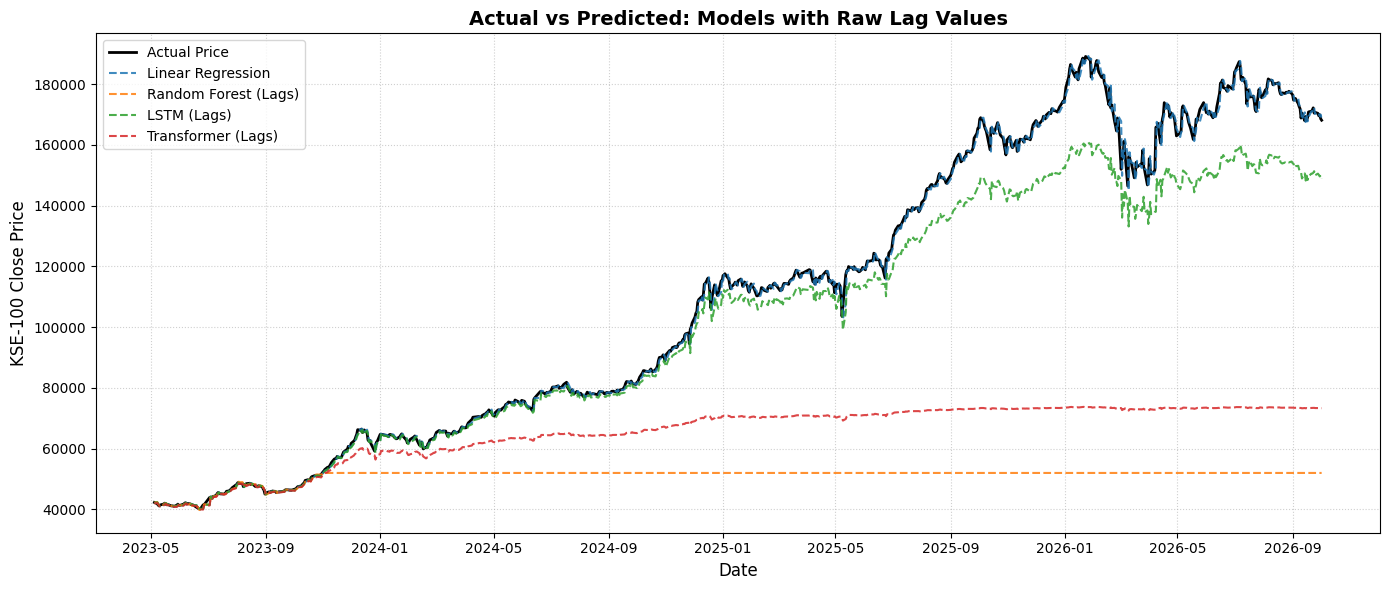

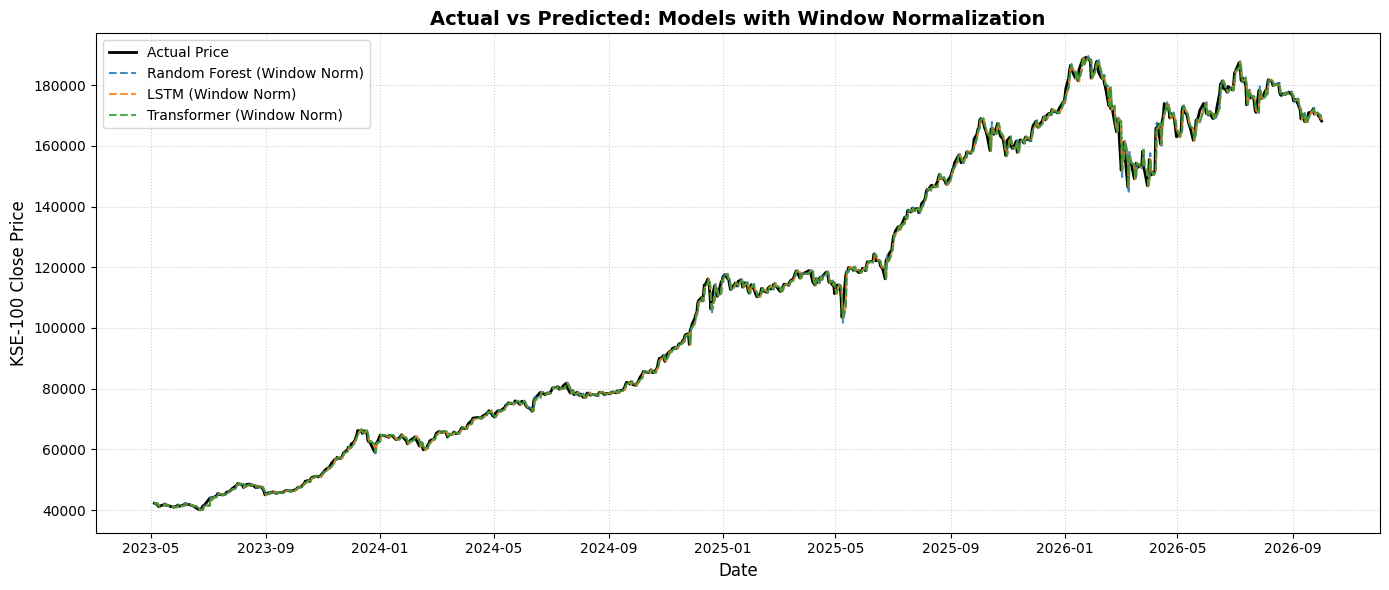

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# ---------------------------------------------------------
# 1. Reproducibility & Setup
# ---------------------------------------------------------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

# ---------------------------------------------------------
# 2. Data Loading & Chronological Split
# ---------------------------------------------------------
file_path = "/kaggle/input/datasets/raoahmadnasir/data-set/KSE100_cleaned_with_lags.xlsx"
df = pd.read_excel(file_path, sheet_name="Clean_Data")
df = df.sort_values("Date").reset_index(drop=True)

feats = ["y_t-1", "y_t-2", "y_t-3", "y_t-4"]
target = "Close"
data = df.dropna(subset=[target] + feats).reset_index(drop=True)

split = int(len(data) * 0.85)
pool, test = data.iloc[:split].copy(), data.iloc[split:].copy()

test_dates = pd.to_datetime(test["Date"])
y_test = test[target].values
base_test = test["y_t-1"].values

# ---------------------------------------------------------
# 3. Model Definitions (PyTorch LSTM & Transformer)
# ---------------------------------------------------------
def to_seq(X):
    return torch.tensor(X[:, ::-1].copy(), dtype=torch.float32).unsqueeze(-1)

def train_nn(model, X_train_t, y_train_t, epochs, batch_size, lr):
    model.train()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    dataset = TensorDataset(X_train_t, y_train_t)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)
    for _ in range(epochs):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
    return model

def predict_nn(model, X_test_t):
    model.eval()
    with torch.no_grad():
        return model(X_test_t.to(device)).cpu().numpy()

class LSTMNet(nn.Module):
    def __init__(self, hidden_size, num_layers, dropout):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        return self.fc(out[:, -1])

class TransformerNet(nn.Module):
    def __init__(self, d_model, nhead, num_layers, dropout, seq_len=4):
        super().__init__()
        self.inp = nn.Linear(1, d_model)
        self.pos = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)
        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=d_model * 2,
            dropout=dropout, batch_first=True
        )
        self.enc = nn.TransformerEncoder(enc_layer, num_layers=num_layers, enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, 1)

    def forward(self, x):
        h = self.enc(self.inp(x) + self.pos)
        return self.fc(h[:, -1])

# ---------------------------------------------------------
# 4. Fit & Predict: Models with Raw Lag Values
# ---------------------------------------------------------
# 4.1 Linear Regression
lr_model = LinearRegression().fit(pool[feats], pool[target])
pred_lr = lr_model.predict(test[feats])

# 4.2 Random Forest (Best: 300 est, depth 10, leaf 5, feat 1.0)
rf_lag = RandomForestRegressor(
    n_estimators=300, max_depth=10, min_samples_leaf=5,
    max_features=1.0, random_state=SEED, n_jobs=-1
).fit(pool[feats], pool[target])
pred_rf_lag = rf_lag.predict(test[feats])

# Scaling for Raw Lag Neural Networks
sx_lag, sy_lag = MinMaxScaler(), MinMaxScaler()
sx_lag.fit(pool[feats].values)
sy_lag.fit(pool[[target]].values)

Xpool_lag_t = to_seq(sx_lag.transform(pool[feats].values))
ypool_lag_t = torch.tensor(sy_lag.transform(pool[[target]].values), dtype=torch.float32)
Xtest_lag_t = to_seq(sx_lag.transform(test[feats].values))

# 4.3 LSTM Raw Lags (Best: hidden 32, layer 1, drop 0.0, lr 0.01, batch 64, ep 64)
lstm_lag = LSTMNet(hidden_size=32, num_layers=1, dropout=0.0).to(device)
lstm_lag = train_nn(lstm_lag, Xpool_lag_t, ypool_lag_t, epochs=64, batch_size=64, lr=0.01)
pred_lstm_lag = sy_lag.inverse_transform(predict_nn(lstm_lag, Xtest_lag_t)).ravel()

# 4.4 Transformer Raw Lags (Best: d_model 32, nhead 2, layers 2, drop 0.0, lr 0.001, batch 64, ep 19)
tf_lag = TransformerNet(d_model=32, nhead=2, num_layers=2, dropout=0.0).to(device)
tf_lag = train_nn(tf_lag, Xpool_lag_t, ypool_lag_t, epochs=19, batch_size=64, lr=0.001)
pred_tf_lag = sy_lag.inverse_transform(predict_nn(tf_lag, Xtest_lag_t)).ravel()

# ---------------------------------------------------------
# 5. Fit & Predict: Models with Window Normalization
# ---------------------------------------------------------
# 5.1 Random Forest Window Norm (Best: 300 est, depth 3, leaf 5, feat 1.0)
rel_rf_feats = ["y_t-2", "y_t-3", "y_t-4"]
base_pool = pool["y_t-1"].values
Xpool_rf_rel = pool[rel_rf_feats].values / base_pool.reshape(-1, 1)
ypool_rf_rel = pool[target].values / base_pool
Xtest_rf_rel = test[rel_rf_feats].values / base_test.reshape(-1, 1)

rf_win = RandomForestRegressor(
    n_estimators=300, max_depth=3, min_samples_leaf=5,
    max_features=1.0, random_state=SEED, n_jobs=-1
).fit(Xpool_rf_rel, ypool_rf_rel)
pred_rf_win = rf_win.predict(Xtest_rf_rel) * base_test

# Relative transform for NN models (using all 4 lags relative to y_t-1)
Xpool_rel = pool[feats].values / base_pool.reshape(-1, 1)
ypool_rel = pool[[target]].values / base_pool.reshape(-1, 1)
Xtest_rel = test[feats].values / base_test.reshape(-1, 1)

sx_win, sy_win = StandardScaler(), StandardScaler()
sx_win.fit(Xpool_rel)
sy_win.fit(ypool_rel)

Xpool_win_t = to_seq(sx_win.transform(Xpool_rel))
ypool_win_t = torch.tensor(sy_win.transform(ypool_rel), dtype=torch.float32)
Xtest_win_t = to_seq(sx_win.transform(Xtest_rel))

# 5.2 LSTM Window Norm (Best: hidden 32, layers 2, drop 0.2, lr 0.01, batch 32, ep 8)
lstm_win = LSTMNet(hidden_size=32, num_layers=2, dropout=0.2).to(device)
lstm_win = train_nn(lstm_win, Xpool_win_t, ypool_win_t, epochs=8, batch_size=32, lr=0.01)
pred_lstm_win = sy_win.inverse_transform(predict_nn(lstm_win, Xtest_win_t)).ravel() * base_test

# 5.3 Transformer Window Norm (Best: d_model 32, nhead 4, layers 2, drop 0.1, lr 0.01, batch 64, ep 22)
tf_win = TransformerNet(d_model=32, nhead=4, num_layers=2, dropout=0.1).to(device)
tf_win = train_nn(tf_win, Xpool_win_t, ypool_win_t, epochs=22, batch_size=64, lr=0.01)
pred_tf_win = sy_win.inverse_transform(predict_nn(tf_win, Xtest_win_t)).ravel() * base_test

# ---------------------------------------------------------
# 6. Plotting the Charts
# ---------------------------------------------------------
# Chart 1: Raw Lag Models vs Actual
plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test, label="Actual Price", color="black", linewidth=2.0)
plt.plot(test_dates, pred_lr, label="Linear Regression", linestyle="--", alpha=0.85)
plt.plot(test_dates, pred_rf_lag, label="Random Forest (Lags)", linestyle="--", alpha=0.85)
plt.plot(test_dates, pred_lstm_lag, label="LSTM (Lags)", linestyle="--", alpha=0.85)
plt.plot(test_dates, pred_tf_lag, label="Transformer (Lags)", linestyle="--", alpha=0.85)
plt.title("Actual vs Predicted: Models with Raw Lag Values", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("KSE-100 Close Price", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Chart 2: Window Normalization Models vs Actual
plt.figure(figsize=(14, 6))
plt.plot(test_dates, y_test, label="Actual Price", color="black", linewidth=2.0)
plt.plot(test_dates, pred_rf_win, label="Random Forest (Window Norm)", linestyle="--", alpha=0.85)
plt.plot(test_dates, pred_lstm_win, label="LSTM (Window Norm)", linestyle="--", alpha=0.85)
plt.plot(test_dates, pred_tf_win, label="Transformer (Window Norm)", linestyle="--", alpha=0.85)
plt.title("Actual vs Predicted: Models with Window Normalization", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("KSE-100 Close Price", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

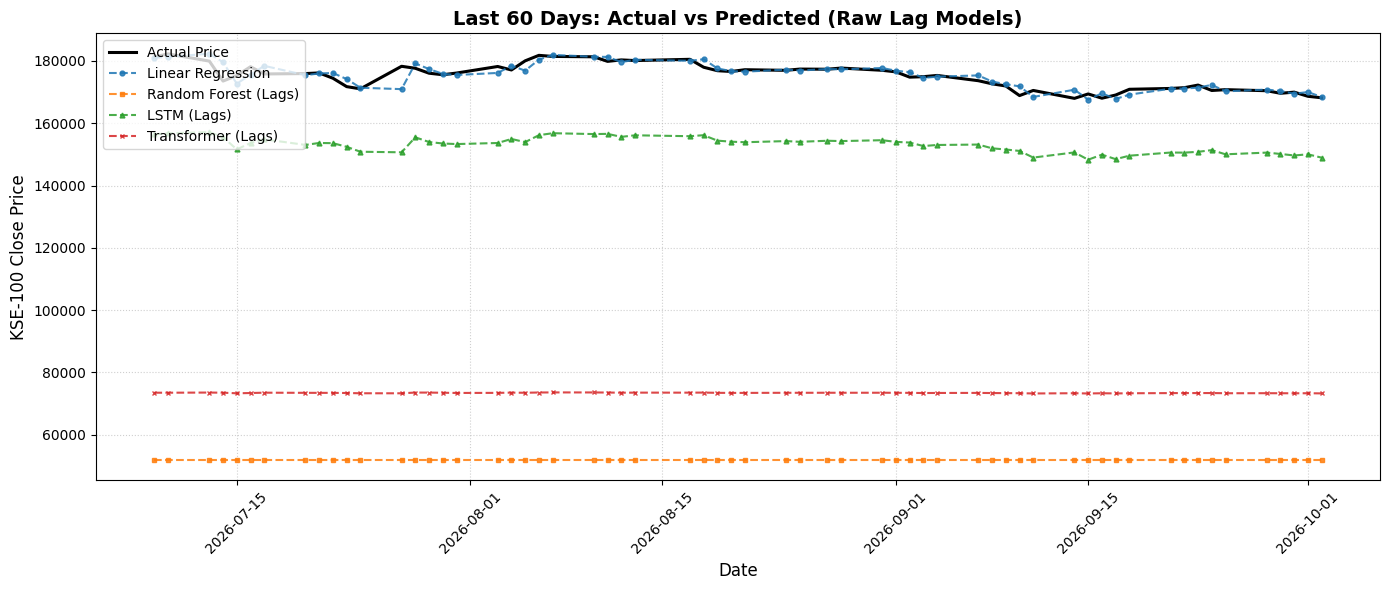

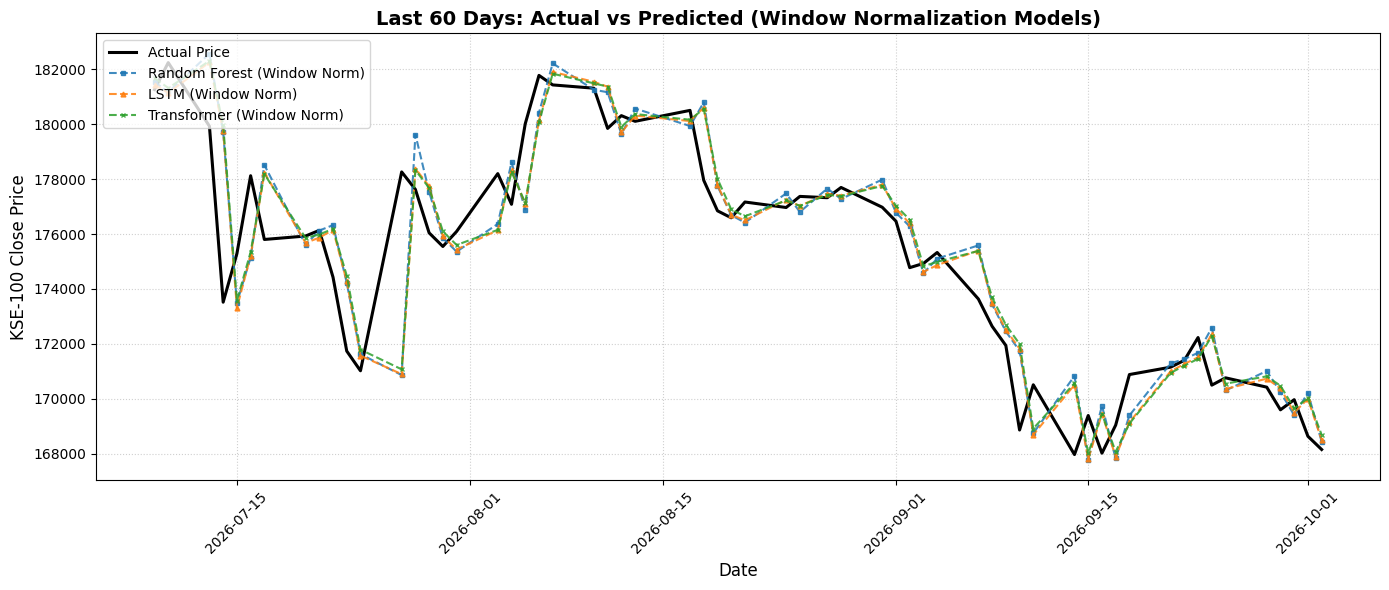

In [3]:
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Slice the Last 60 Days of Test Data & Predictions
# ---------------------------------------------------------
N = 60

# Slice dates and ground truth
dates_60 = test_dates.iloc[-N:] if hasattr(test_dates, "iloc") else test_dates[-N:]
actual_60 = y_test[-N:]

# Slice raw lag predictions
lr_60 = pred_lr[-N:]
rf_lag_60 = pred_rf_lag[-N:]
lstm_lag_60 = pred_lstm_lag[-N:]
tf_lag_60 = pred_tf_lag[-N:]

# Slice window normalization predictions
rf_win_60 = pred_rf_win[-N:]
lstm_win_60 = pred_lstm_win[-N:]
tf_win_60 = pred_tf_win[-N:]

# ---------------------------------------------------------
# 2. Chart 1: Last 60 Days - Raw Lag Models vs Actual
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(dates_60, actual_60, label="Actual Price", color="black", linewidth=2.2)
plt.plot(dates_60, lr_60, label="Linear Regression", linestyle="--", marker="o", markersize=3.5, alpha=0.85)
plt.plot(dates_60, rf_lag_60, label="Random Forest (Lags)", linestyle="--", marker="s", markersize=3.5, alpha=0.85)
plt.plot(dates_60, lstm_lag_60, label="LSTM (Lags)", linestyle="--", marker="^", markersize=3.5, alpha=0.85)
plt.plot(dates_60, tf_lag_60, label="Transformer (Lags)", linestyle="--", marker="x", markersize=3.5, alpha=0.85)

plt.title("Last 60 Days: Actual vs Predicted (Raw Lag Models)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("KSE-100 Close Price", fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. Chart 2: Last 60 Days - Window Normalization vs Actual
# ---------------------------------------------------------
plt.figure(figsize=(14, 6))
plt.plot(dates_60, actual_60, label="Actual Price", color="black", linewidth=2.2)
plt.plot(dates_60, rf_win_60, label="Random Forest (Window Norm)", linestyle="--", marker="s", markersize=3.5, alpha=0.85)
plt.plot(dates_60, lstm_win_60, label="LSTM (Window Norm)", linestyle="--", marker="^", markersize=3.5, alpha=0.85)
plt.plot(dates_60, tf_win_60, label="Transformer (Window Norm)", linestyle="--", marker="x", markersize=3.5, alpha=0.85)

plt.title("Last 60 Days: Actual vs Predicted (Window Normalization Models)", fontsize=14, fontweight="bold")
plt.xlabel("Date", fontsize=12)
plt.ylabel("KSE-100 Close Price", fontsize=12)
plt.xticks(rotation=45)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()